<img src="../img/logo.jpeg" width= 200px>   

# Agentes con LangGraph     

LangGraph es una librería de LangChain que nos ofrece un framework para definir, coordinar y ejecutar multiples agentes de forma estructurada. A través de la creación y uso de **grafos cíclicos**.   

En LangGraph, el estado del grafo organiza el orden de tareas del agente, como el uso de herramientas y las llamadas a LLM, en un flujo de trabajo. El grafo utiliza un estado del agente para rastrear el progreso del agente en forma de texto, ayudando a determinar cuando se completa una tarea.    

A continuación, se construye un chatbot educativo que va a usar un LLM para responder preguntas.   

Para construir un agente sencillo, tan solo es necesario utilizar tres nodos y dos aristas, como se observa en el siguiente esquema:

<img src="../img/chatbotSchema.png" width=200 style="display: block; margin: auto;">

En LangGraph, como ya se ha mencionado, los nodos representan fuciones/tareas, como generar una respuesta o llamar a una herramienta ("tool"), mientras que las aristas ("edges") definen las conexiones que existen entre los nodos.   

Los nodos **INICIO (START)** y **FIN (END)** marcan el principio y el final del flujo de trabajo y se importan directamente desde LangGraph.

### Paso 0. Configuración previa

In [ ]:
# =====================================================================================
# 🔑  Introduce tus API keys en la linea correspondiente antes de ejecutar el notebook
# ==============================================================
import os


# Carga tu API key de Hugging Face en la siguiente variable. 
# Puedes obtenerla en https://huggingface.co/settings/tokens

HF_API_KEY = ""  # 👈 Pon aquí tu token de HuggingFace



# Carga tu API key de Hugging Face en la siguiente variable. 
# Puedes obtenerla en https://console.groq.com/keys
GROQ_API_KEY = ""  # 👈 Pon aquí tu token de GROQ


# Configura la variable de entorno para Hugging Face
os.environ["HUGGINGFACEHUB_API_TOKEN"] = HF_API_KEY
os.environ["GROQ_API_KEY"] = GROQ_API_KEY

print("✅ ¡API keys configuradas y listas para usar!")

✅ ¡API keys configuradas y listas para usar!


In [2]:
# instalar librería langgraph - Sólo la primera vez que se ejecute el notebook
%pip install langgraph

Note: you may need to restart the kernel to use updated packages.


### Paso 1. - Importamos librerías y módulos necesarios.

In [17]:
from langchain_huggingface import HuggingFaceEndpoint, ChatHuggingFace # conectamos con la API de Hugging Face
from langchain_groq import ChatGroq

In [18]:
# Módulos para estructurar texto del chatbot
from typing import Annotated
from typing_extensions import TypedDict

# Módulos de LangGraph para definir el grafo de conversación
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages


### Paso 2. - Configuramos el LLM que vamos a usar (GPT-OSS-20B en GROQ):

In [19]:
# llm = HuggingFaceEndpoint(
#     repo_id="Qwen/Qwen3-8B",                                            # Modelo gratuito en HF Inference API
#     temperature=0.01,                                                   # Cercano a 0 para respuestas más determinísticas
#     max_new_tokens=1024,                                                # Número máximo de tokens a generar.
#     task="text-generation"                                              # Tipo de tarea que queremos realizar con el modelo. En este caso, generación de texto.
# )


# --- Inicializar LLM desde Groq ---  Son modelos conversacionales de gran tamaño, optimizados para generar respuestas coherentes y contextualmente relevantes en conversaciones.
llm = ChatGroq(
    model="openai/gpt-oss-120b", # cambiamos a un modelo más grande para mejorar la calidad de las respuestas 
    temperature=0.1,
    max_tokens=1024,
)

In [20]:
# model = ChatHuggingFace(llm=llm)
model = llm

### Paso 3.- Definimos el estado:    

En la clase `State()` se definen los mensajes con metadatos para estructurar la conversación entre el usuario y el agente. Estos mensajes se utilizarán para alimentar el grafo de conversación y permitir que el agente responda de manera coherente y contextualizada a las consultas del usuario.    
El tipo de dato `Annotated` se utiliza para agregar metadatos a la lista de mensajes, en este caso, el decorador `add_messages() `que indica que esta lista debe ser tratada como un historial de mensajes para el grafo de conversación.   

Lo siguiente es inicializar el **grafo de estados (StateGraph)**. Para ello creamos una instancia de `StateGraph` utilizando la clase `State` que hemos definido anteriormente para estructurar el estado del grafo con los mensajes de la conversación.      
El generador de grafos (`StateGraph`) nos permitirá definir las transiciones entre diferentes estados de la conversación, facilitando la gestión del diálogo entre el usuario y el agente.

In [21]:
class State(TypedDict):
    
    messages: Annotated[list, add_messages()] # lista que almacena toda la conversación.
    
# Inicializamos el grafo de estados (StateGraph) 
graph_builder = StateGraph(State) # 

### Paso 4.- Montaje de los nodos.   

Los **nodos** suelen ser funciones de Python que realizan una tarea específica, como por ejemplo

- Interactuar con un LLM
- Llamar a una herramienta o API
- Realizar alguna manipulación de datos
- Recibir la información del usuario
- Ejecutar la lógica empresarial

En nuestro caso, se define el **nodo de la función principal** denominado ***"chatbot"***, que acepta la clase `State`:    
- Se define una función `chatbot` que toma los mensajes de estado (state) como entrada y devuelve un nuevo estado con los mensajes actualizados.
- Dentro de la función, se usa el modelo de lenguaje (llm) para generar una respuesta basada en el historial de mensajes almacenado en el estado actual. 
- La función devuelve un diccionario con la clave "messages" que contiene la respuesta generada por el modelo, lo que permite al grafo de conversación actualizar el estado con la nueva información y continuar la interacción de manera coherente.   

LangGraph se encarga *automáticamente* de fusionar esa respuesta con el historial existente (no lo reemplaza, lo actualiza).

                   ` Estado actual (mensajes) → modelo LLM → nuevo mensaje → estado actualizado `  

Es, por tanto, el núcleo de nuestro agente conversacional: recibe el historial, genera una respuesta y la devuelve para que el grafo la incorpore al estado.

📌 Mencionar aquí que el *"estado"* es un objeto que se va actualizando por parte de los nodos a lo largo del tiempo, gestionando la situación interna del sistema. Puede añadirse o anularse, conteniendo elementos como:
- *Historia de la conversación*: Una lista de mensajes entre el agente y el usuario.
- *Datos contextuales*: Información relevante para la tarea o interacción actual.
- *Variables internas*: Indicadores, contadores u otras variables para seguir el progreso y el comportamiento del agente.


In [22]:
def chatbot(state: State):
    return {"messages":
        [model.invoke(state["messages"])]}

Se añade el nodo del chatbot al grafo. Para ello usamos la sintaxis `graph.add_node(nombre, valor)`, que en nuestro ejemplo queda como sigue:

In [23]:
graph_builder.add_node("chatbot", chatbot) # añadimos un nodo al grafo que representa la función chatbot.

Continuamos añadiendo *nodos* y *aristas*.    

- Definimos el principio y el final del grafo de conversación:   
    - Se define la transición desde el estado inicial (START) al nodo del chatbot, indicando que la conversación comienza con la función chatbot.
    - Se define la transición desde el nodo del chatbot al estado final (END), indicando que la conversación puede finalizar después de que el chatbot haya respondido.
    - Finalmente, se compila el grafo para que este listo y pueda ejecutarse. Esto conlleva la validación de las transiciones y preparar la estructura del grafo para manejar las conversaciones de manera eficiente.   

In [24]:
# Definimos la transición desde el estado inicial (START) al nodo del chatbot.
graph_builder.add_edge(START, "chatbot") 
# Definimos la transición desde el nodo del chatbot al estado final (END).
graph_builder.add_edge("chatbot", END) 
# Compilamos el grafo.
graph = graph_builder.compile() 

En ***LangGraph***, la transmisión de eventos desde un grafo permite procesar los pasos del flujo de trabajo de un agente en tiempo real. A medida que se transmite, cada evento representa un solo paso en el grafo, como generar una respuesta o llamar a una herramienta.   
Esto permite rastrear el progreso del agente del chatbot, mostrando respuestas tan pronto como estas estén listas.    

### Paso 5.- Generación de respuestas del ChatBot.

Para generar las respuestas de nuestro ChatBot empezamos definiendo una función que se encargará de ejecutar el chatbot basado en el input del usuario, lo que nos permitirá interactuar con el agente de manera sencilla y directa.   
Para ejecutar el grafo utilizamos la función `stream`, pasando un estado inicial que contiene el mensaje del usuario. La función `stream` devuelve un generador que produce eventos a medida que el grafo procesa la conversación.
Se va iterando sobre los valores de cada evento generado por el grafo, lo que permite acceder a las respuestas del chatbot a medida que se generan en tiempo real.    
Por último, se imprime la respuesta del agente a medida que se genera, lo que permite ver la interacción en tiempo real entre el usuario y el chatbot.

In [25]:
from IPython.display import display, Markdown                         # imports de librerías y modulos para salida con formato Markdown

def stream_graph_updates(user_input):
    for event in graph.stream({"messages": [("user", user_input)]}):  # ejecutamos el grafo utilizando la función stream.
        for value in event.values():                                  # iteramos sobre los valores de cada evento generado por el grafo.
            for msg in value["messages"]:
                display(Markdown(f"**🤖 Agente:**\n\n{msg.content}")) # imprimimos la respuesta del agente a medida que se genera. (Usamosformato Markdown)

Otra opción sería usar la función `invoke`, donde debe tenerse en cuenta que se realiza la ejecución de toda la conversación, devolviendo el estado final de la misma. Para tener un resultado equivalente al uso de la función `stream` es necesario implementar el código de la siguiente forma:

In [26]:
from IPython.display import display, Markdown   

def get_graph_response(user_message: str):
    result = graph.invoke({"messages": [{"role": "user", "content": user_message}]}) # Llama al grafo con el mensaje del usuario
    display(Markdown(f"**🤖 Agente:**\n\n {result['messages'][-1].content}"))            # Imprime la respuesta del asistente (último mensaje generado por el modelo)

### Paso 6.- Definición de la consulta a lanzar.    

Se define una consulta para el chatbot y seguidamente, se lanza la función para ver la respuesta del agente en tiempo real.

In [27]:
query = "¿Quién es Ray Bradbury?" # definimos una consulta para el chatbot relacionada con el autor Ray Bradbury, lo que nos permitirá ver cómo el agente responde a preguntas de conocimiento general.

Ejecutamos la función `stream_graph_updates` pasando la consulta, lo que iniciará la interacción con el chatbot y mostrará la respuesta del agente basada solo en el *"conocimiento propio"* del LLM.

In [28]:
stream_graph_updates(query) 

**🤖 Agente:**

Ray Brad Bradbury (1920‑2012) fue uno de los escritores más influyentes de la literatura de ciencia‑ficción y fantasía del siglo XX. Nacido el 22 de agosto de 1920 en Waukegan, Illinois (EE. UU.), se trasladó a Los Ángeles cuando era niño, donde pasó gran parte de su vida y carrera.

### Obras más destacadas
| Año | Título | Género / Tema | Comentario |
|-----|--------|---------------|------------|
| 1950 | **"The Martian Chronicles"** | Cuentos y novela corta | Una serie de relatos interconectados sobre la colonización de Marte, que combina ciencia‑ficción con crítica social. |
| 1953 | **"Fahrenheit 451"** | Novela distópica | Ambientada en un futuro donde los libros están prohibidos y los “bomberos” queman cualquier obra escrita; es una reflexión sobre la censura y la pérdida de la cultura. |
| 1951 | **"The Illustrated Man"** | Cuentos | Colección de relatos que exploran la condición humana a través de la tecnología, la alienación y lo sobrenatural. |
| 1962 | **"Something Wicked This Way Comes"** | Fantasía / terror | Novela sobre un circo siniestro que llega a un pequeño pueblo, con temas de miedo, envejecimiento y la lucha entre el bien y el mal. |
| 1972 | **"The Halloween Tree"** | Fantasía juvenil | Viaje mágico a través del tiempo y las tradiciones de Halloween, escrito para un público joven pero con profundidad histórica. |

### Características de su estilo
- **Prosa poética:** Bradbury usaba un lenguaje lírico y evocador, a menudo comparado con la poesía más que con la prosa tradicional de la ciencia‑ficción.
- **Temas recurrentes:** La tecnología versus la humanidad, la censura, la nostalgia por la infancia, la soledad y la capacidad de la imaginación.
- **Humanismo:** A pesar de los escenarios futuristas, sus historias siempre giran en torno a emociones y dilemas humanos universales.

### Legado y reconocimientos
- **Premios:** Ganó varios premios Hugo, un Premio Bram Stoker, el National Medal of Arts (2004) y el World Fantasy Award for Life Achievement (1995), entre otros.
- **Influencia:** Autores como Stephen King, Neil Gaiman y Margaret Atwood citan a Bradbury como una gran influencia. Su obra ha sido adaptada al cine, la televisión, el teatro y el cómic.
- **Activismo:** Fue un defensor ferviente de la libertad de expresión y la preservación de los libros; su famosa frase “Los libros son los mejores amigos del hombre” resume su postura.

### Datos curiosos
- **Autodidacta:** Bradbury nunca asistió a la universidad; aprendió leyendo vorazmente en bibliotecas públicas.
- **Primeros trabajos:** Escribió guiones para la radio y la televisión (incluido “The Twilight Zone”) antes de consolidarse como novelista.
- **Vida larga y productiva:** Publicó su último libro, *“The Last Night of the World”* (una colección de cuentos), a los 90 años.

En resumen, Ray Bradbury es un autor cuya obra trasciende los géneros y sigue resonando por su capacidad de combinar imaginación futurista con una profunda reflexión sobre la condición humana. Su legado continúa inspirando a lectores y creadores de todo el mundo.

Ahora ejecutamos la función `get_graph_response`para comprobar que obtenemos resultados similares, aunque usando la función `invoke` y mostrando un único resultado:

In [29]:
get_graph_response(query) # llamamos a la función get_graph_response para obtener la respuesta del grafo a la consulta definida.    

**🤖 Agente:**

 Ray Brad Bradbury (1920‑2012) fue uno de los escritores más influyentes de la literatura de ciencia‑ficción y fantasía del siglo XX, aunque su obra trasciende esos géneros y se adentra en la poesía, el terror y la reflexión social.

### Breve biografía
| Año | Acontecimiento |
|-----|----------------|
| **1920** | Nace el 22 de agosto en Waukegan, Illinois (EE. UU.). |
| **1930‑1938** | Se muda a Los Ángeles; comienza a escribir cuentos para revistas pulp y a leer a autores como H. G. Wells y Edgar Allan Poe. |
| **1940‑1950** | Publica sus primeros relatos en *Weird Tales* y *Astounding Science Fiction*. Su primer libro importante, **“The Martian Chronicles”** (1950), reúne relatos sobre la colonización de Marte. |
| **1953** | Publica **“Fahrenheit 451”**, novela distópica que se convierte en un clásico de la literatura mundial. |
| **1960‑1970** | Escribe novelas, guiones para radio, televisión y cine (participó en la adaptación de *The Martian Chronicles* para TV). |
| **1990‑2000** | Recibe numerosos premios (Hugo, Nebula, Bram Stoker, National Medal of Arts). Publica obras de reflexión sobre la escritura y la imaginación, como **“Zen in the Art of Writing”**. |
| **2012** | Muere el 5 de junio en Los Ángeles, a los 91 años. |

### Obras más destacadas
- **“Fahrenheit 451”** (1953) – Distopía sobre una sociedad que quema libros y suprime el pensamiento crítico.  
- **“The Martian Chronicles”** (1950) – Colección de relatos que exploran la colonización de Marte y la condición humana.  
- **“The Illustrated Man”** (1951) – Relatos interconectados que combinan ciencia‑ficción y horror.  
- **“Something Wicked This Way Comes”** (1962) – Novela de terror/fantasía sobre un circo siniestro.  
- **“Dandelion Wine”** (1957) – Nostálgico retrato de la infancia en un pequeño pueblo de Illinois.  

### Estilo y temáticas
- **Humanismo**: A pesar de los escenarios futuristas, sus historias siempre giran en torno a emociones, miedos y esperanzas humanas.  
- **Crítica social**: Aborda la censura, el consumismo, la tecnología deshumanizante y la pérdida de la imaginación.  
- **Lenguaje poético**: Su prosa es rica en metáforas y ritmo, lo que le valió elogios tanto de críticos de ciencia‑ficción como de literatura general.  

### Reconocimientos
- **Premios Hugo** (3 veces) y **Nebula** (2 veces).  
- **Premio Bram Stoker** (por “The October Country”).  
- **National Medal of Arts** (2004) otorgada por el presidente George W. Bush.  
- **Ray Bradbury Award for Outstanding Dramatic Presentation** (creado por la Academia de Ciencias Ficción, Fantasía y Horror en su honor).  

### Legado
Ray Bradbury es recordado como el “poeta de la ciencia‑ficción”. Sus obras siguen siendo leídas en escuelas y universidades, adaptadas al cine, la televisión y el teatro, y continúan inspirando a escritores, cineastas y lectores a cuestionar el rumbo de la sociedad y a valorar la imaginación como herramienta esencial para el progreso humano.

El comportamiento es el mismo en un grafo simple, pero con `invoke()` el texto aparece todo de golpe al final, no de forma progresiva.      

La siguiente tabla refleja las situaciones en las que es aconsejable usar 'invoke' o 'stream':     


| invoke() | stream() |
|----------|----------|
|Resultado procesado programáticamente(guardar en BBDD, hacer cálculos,...)| Usuario esperando respuesta en tiempo real|
|Script / pipeline interno (sin mostrar progreso)| Grafo con múltiples nodos y es necesario mostrar progreso|
|No hay problemas de espera| Evitar sensación de 'cuelgue'|
|Proceso de testeo o depuración| Se construye o se usa una interfaz (al estilo de los chats tipo ChatGPT)|     

En resumen:   
- Si hay un **humano** mirando la pantalla → `stream()`
- Si es una **máquina** procesando el resultado → `invoke()`

### Paso 7. - Generando una imagen del grafo.   

Vamos a mostrar una representación visual del grafo de conversación utilizando la función `draw_mermaid_png`, lo que nos permitirá entender mejor la estructura y las transiciones del citado grafo.

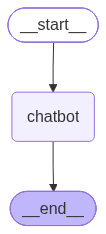

In [30]:
from IPython.display import Image, display 

try:
    display(Image(graph.get_graph().draw_mermaid_png())) # representación visual del grafo de conversación
    
except Exception as e:
    print("Se necesitan dependencias adicionales para mostrar el grafo visual.")

### Paso 8.- Añadiendo herramientas a nuestro ChatBot.     

Las herramientas dotadas de funcionalidades API (***API tools***) permiten aumentar las capacidades de los agentes chatbot al conceder acceso a recursos externos como sitios de noticias, bases de datos, redes sociales, ...      

Con **LangGraph** se va a proceder a ampliar el conocimiento del chatbot creado anteriormente, incluyendo una API de Wikipedia.    

Para ello, lo que hacemos seguidamente es instalar la biblioteca `wikipedia-api` para que nuestro agente acceda a la información de Wikipedia.

In [31]:
%pip install wikipedia-api wikipedia

  Using cached wikipedia-1.4.0.tar.gz (27 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached tenacity-9.1.4-py3-none-any.whl.metadata (1.2 kB)
  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
Using cached tenacity-9.1.4-py3-none-any.whl (28 kB)
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11757 sha256=fd3512ec0ddb85472ef5ff465cdf7f2cd14ca5ae68983b51b8ad62d05cefbf61
  Stored in directory: /home/jordi/.cache/pip/wheels/30/24/d3/9d46daa49494cef2f32dc9a8f203aac1f10cec980adba03d1f
Successfully built wikipedia
  Attempting uninstall: tenacity
    Found existing installation: tenacity 9.2.1
    Uninstalling tenacity-9.2.1:
      Successfully uninstalled tenacity-9.2.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [wikipedia]/5 [wikipedia-api]]
Note: you may need to restart t

Instalamos también los módulos necesarios para crear la tool de Wikipedia:
- Por un lado, importamos la clase `WikipediaAPIWrapper` para crear una herramienta que permita al agente acceder a información de Wikipedia, lo que ampliará las capacidades del agente para responder preguntas basadas en conocimientos generales y específicos obtenidos de esta fuente y,
- por otra parte, importamos la clase `WikipediaQueryRun` para ejecutar consultas específicas a Wikipedia, lo que permitirá al agente obtener información detallada y precisa de esta fuente cuando sea necesario durante la conversación.    

In [32]:

from langchain_community.utilities import WikipediaAPIWrapper 
from langchain_community.tools import WikipediaQueryRun 

### Paso 9.- Inicializar la herramienta de Wikipedia.   

Se crea una instancia de WikipediaAPIWrapper para interactuar con la API de Wikipedia, configurando el parámetro top_k_results a 1 para limitar los resultados a la información más relevante obtenida de Wikipedia.      

Esto permitirá al agente acceder a datos actualizados y específicos durante las conversaciones, mejorando su capacidad para responder preguntas que requieran información adicional más allá de su conocimiento preentrenado.     

*Nota:* El parámetro `top_k_results` esta cargado con el valor 1 porque tan solo nos interesa el valor del primer resultado de la consulta, que damos por supuesto que es el que realmente buscamos.
                                                   

In [33]:
wikipedia = WikipediaAPIWrapper(top_k_results=1) 

### Paso 10.- Generación de la tool de Wikipedia.    

Aquí *se crea* la herramienta de Wikipedia utilizando `WikipediaQueryRun`,lo que permitirá al agente ejecutar consultas específicas a Wikipedia y obtener información relevante durante las conversaciones.   

Una vez creada la herramienta, se añade a la lista de herramientas del agente.

In [34]:
wikipedia_tool = WikipediaQueryRun(api_wrapper=wikipedia) 
tools = [wikipedia_tool] # añadimos la herramienta de Wikipedia a la lista de herramientas disponibles para el agente.

### Paso 11.- Integración de la nueva tool al grafo.    

Se vincula la herramienta de Wikipedia al grafo para que el agente pueda utilizarla durante la conversación.

In [35]:
model_with_tools = model.bind_tools(tools) # vinculamos el modelo de lenguaje (llm) con la lista de herramientas.

### Paso 12.- Modificación del chatbot para que utilice las nuevas herramientas.    

Se modifica la función chatbot para que utilice el modelo de lenguaje vinculado con las herramientas, lo que permitirá al agente acceder a la información de Wikipedia cuando sea necesario durante la conversación, mejorando así su capacidad para responder preguntas que requieran conocimientos adicionales.

In [36]:
def chatbot(state: State):
    return {"messages":
        [model_with_tools.invoke(state["messages"])]}

Añadimos nuevos módulos y librerias, que nos proporcionan la posibilidad de añadir estructuras condicionales a las herramientas y nodos del grafo

In [37]:
from langgraph.prebuilt import ToolNode, tools_condition 

### Paso 13.- Reiniciar el grafo de estados.


In [38]:
graph_builder = StateGraph(State) 
# Añadimos el nodo del chatbot al grafo
graph_builder.add_node("chatbot", chatbot) 

Creamos un **ToolNode** para la herramienta de Wikipedia.   

- Se crea un nodo de herramienta (ToolNode) que contiene la herramienta de Wikipedia.
- Se añade el nodo de herramientas al grafo, lo que permitirá al agente acceder a la herramienta de Wikipedia durante la conversación.

In [39]:
tool_node = ToolNode(tools=[wikipedia_tool]) 
graph_builder.add_node("tools", tool_node) 

### Paso 14.- Establecemos la nueva 'variación' en el flujo del grafo.    

Proporcionamos una condicion para dirigir desde el chabot al nodo de herramientas cuando el agente necesite acceder a Wikipedia para responder una consulta.    
Para ello, se añade una transición condicional desde el nodo del chatbot al nodo de herramientas, utilizando la función `tools_condition` para determinar cuándo el agente debe acceder a la herramienta de Wikipedia durante la conversación. 

In [40]:
graph_builder.add_conditional_edges("chatbot",tools_condition)

Se conectan las tools **"hacia atrás"** al chatbot para que el agente pueda volver a responder después de usar la herramienta de Wikipedia.   

Después se añaden los nodos de *inicio* y *fin* del grafo para completar la estructura de la conversación.

In [41]:
graph_builder.add_edge("tools", "chatbot") # añadimos una transición desde el nodo de herramientas de vuelta al nodo del chatbot.
graph_builder.add_edge(START, "chatbot") # definimos la transición desde el estado inicial (START) al nodo del chatbot.
graph_builder.add_edge("chatbot", END) # definimos la transición desde el nodo del chatbot al estado final (END).

### Paso 15.- Compilación del grafo.

In [42]:
graph = graph_builder.compile()

### Paso 16.- Visualización del grafo modificado.   

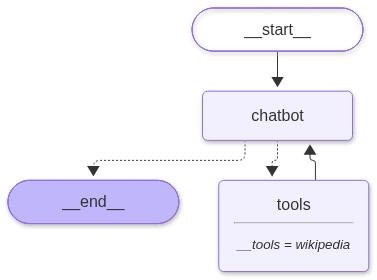

In [43]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

### Paso 17.- Probamos la modificación con una consulta *ad hoc*

In [44]:
query = "¿Quién es Ray Bradbury según Wikipedia?"

for event in graph.stream({"messages": [("user", query)]}):
    for value in event.values():
        for msg in value["messages"]:
            if msg.content:
                display(Markdown(f"**🤖 Agente:**\n\n{msg.content}"))

**🤖 Agente:**

Page: Ray Bradbury
Summary: Ray Douglas Bradbury (US:  BRAD-berr-ee; August 22, 1920 – June 5, 2012) was an American author and screenwriter. One of the most celebrated 20th-century American writers, he worked in a variety of genres, including fantasy, science fiction, horror, mystery, and realistic fiction.
Bradbury is best known for his novel Fahrenheit 451 (1953) and his short-story collections The Martian Chronicles (1950), The Illustrated Man (1951), and The October Country (1955). Other notable works include the coming of age novel Dandelion Wine (1957), the dark fantasy Something Wicked This Way Comes (1962) and the fictionalized memoir Green Shadows, White Whale (1992). He also wrote and consulted on screenplays and television scripts, including Moby Dick and It Came from Outer Space. Many of his works were adapted into television and film productions as well as comic books. Bradbury also wrote poetry which has been published in several collections, such as They Have Not Seen the Stars (2001).
The New York Times called Bradbury "An author whose fanciful imagination, poetic prose, and mature understanding of human character have won him an international reputation" and "the writer most responsible for bringing modern science fiction into the literary mainstream".

**🤖 Agente:**

Según Wikipedia, **Ray Douglas Bradbury** (22 de agosto de 1920 – 5 de junio de 2012) fue un autor y guionista estadounidense, considerado uno de los escritores estadounidenses más célebres del siglo XX. Trabajó en una amplia variedad de géneros, entre ellos la fantasía, la ciencia‑ficción, el horror, el misterio y la ficción realista.

### Obras más destacadas
- **Fahrenheit 451** (1953) – novela distópica sobre la censura y la quema de libros.  
- **Crónicas marcianas** (The Martian Chronicles, 1950) – colección de relatos sobre la colonización de Marte.  
- **El hombre ilustrado** (The Illustrated Man, 1951) – otra colección de cuentos de ciencia‑ficción.  
- **El país de octubre** (The October Country, 1955) – relatos de terror y fantasía.  
- **Dandelion Wine** (1957) – novela de iniciación.  
- **Algo siniestro se acerca** (Something Wicked This Way Comes, 1962) – fantasía oscura.  
- **Green Shadows, White Whale** (1992) – memorias ficcionalizadas.

### Otros trabajos
Bradbury también escribió y colaboró en guiones de cine y televisión (por ejemplo, *Moby Dick* y *It Came from Outer Space*), y sus obras han sido adaptadas a series, películas, cómics y obras de teatro. Además, publicó poesía en varios libros, como *They Have Not Seen the Stars* (2001).

### Reconocimientos
El *New York Times* lo describió como “un autor cuya imaginación fantasiosa, prosa poética y comprensión madura del carácter humano le han granjeado una reputación internacional”, y lo consideró “el escritor más responsable de llevar la ciencia‑ficción moderna al mainstream literario”.

<!-- Nota -->
<div style="background-color: #fff3cd; color: #000000 ;padding: 15px; border-radius: 5px;">    

#### 📌 Nota.    
En esta última respuesta, el agente está mostrando todos los mensajes del historial, no solo el final:    

    1-El modelo genera una primera respuesta en inglés (su idioma natural por defecto).   
    2-La herramienta de Wikipedia devuelve texto
    3-El modelo genera una segunda respuesta en castellano (porque la pregunta estaba en castellano)

Nuestro código, usando un bucle, nos muestra ambas respuestas al iterar sobre todos los mensajes con contenido.

📢❗🚨 En ocasiones, por problemas de Timeout, se generan errores de comunicación. Podemos reintentar lanzar la consulta o cambiar el idioma de la consulta ('Who is Ray Bradbury according to Wikipedia')

</div>